# Data Preparation 2: Prepare ELSET Data
Acquire General Perturbation (gp) Data in form of Orbit Mean-Element Messages (OMMs) from [space-track.org](https://www.space-track.org/). Retrieve all OMMs for each object and then randomly select one Epoch for each object
Last Updated: 2025-03-17

In [ ]:
# imports 
from spacetrack import SpaceTrackClient
import pandas as pd
import time
import json
import os
from httpx import ReadTimeout
import matplotlib.pyplot as plt
from datetime import datetime, timedelta

## 1. Retrieve all available Epochs of OMMs per object


In [ ]:
# Space-Track.org API authentication 
# read Space-Track.org credentials from external file (username in line 1, password in line 2)
with open('../SpaceTrackCredentials.txt', 'r') as file:
    credentials = file.read().splitlines()

username = credentials[0]
password = credentials[1]

# create a SpaceTrackClient instance
st = SpaceTrackClient(username, password) 

try:
    # Try fetching a single SATCAT entry to verify authentication
    test_data = st.gp(limit=1, format='json')
    print("Successfully authenticated with Space-Track.org!")
except Exception as e:
    print(f"Failed to authenticate with Space-Track.org: {e}")

Successfully authenticated with Space-Track.org!


In [151]:
# Read the NORAD IDs from the file
norad_ids = pd.read_csv("../Data/NoradIDs.csv")
print(f"Objects: {len(norad_ids)}")

Objects: 25798


Retrieve OMMs in chunks and adjust number of requested objects automatically when the number of returned objects gets too high. Save only Norad ID and Epoch to save RAM. 

In [ ]:
# settings
chunk_size = 32
request_delay = 5
request_limit = 300
limit_delay = 1200
output_file = '../Data/AllEpochsLFS.csv'

# start variables
index = 22812
total_objects = len(norad_ids)
consecutive_timeouts = 0
consecutive_successful = 0
request_count = 1

# main loop
while index < total_objects:
    # Check if the API request limit has been reached
    if request_count >= request_limit:
        print(f"Reached {request_count} API requests. Waiting for {limit_delay} seconds.")
        time.sleep(limit_delay)
        request_count = 0

    # query start
    current_chunk = norad_ids[index:index + chunk_size] 
    api_url = f"https://www.space-track.org/basicspacedata/query/class/gp_history/NORAD_CAT_ID/{','.join(current_chunk["NORAD_CAT_ID"].astype(str))}/format/json"
    print(f"\nRequest {request_count}: Querying {len(current_chunk)} objects from index {index} to {index+len(current_chunk)-1}...")
    print(f"API URL: {api_url}")


    # try fetching data for chunk
    try:
        request_count += 1
        time.sleep(request_delay)
        omm_data = st.gp_history(norad_cat_id=','.join(current_chunk["NORAD_CAT_ID"].astype(str)), format='json')
        omm_data_json = json.loads(omm_data)
        # check if data was returned
        if not omm_data_json:
            print("No data returned for this chunk. Skipping to the next chunk.")
            index += chunk_size
            consecutive_timeouts = 0
            consecutive_successful += 1
            continue
        omm_data_epochs = [{'NORAD_CAT_ID': entry['NORAD_CAT_ID'], 'EPOCH': entry['EPOCH']} for entry in omm_data_json] # extract only ID and Epoch to save RAM
    # catch exceptions
    except ReadTimeout:
        consecutive_timeouts += 1
        consecutive_successful = 0
        print(f"Timeout error ({consecutive_timeouts})")
        if consecutive_timeouts >= 2 and chunk_size > 1: # halve chunk size if api response is too large
            new_chunk_size = chunk_size // 2
            print(f"Two consecutive timeouts. Reducing chunk size from {chunk_size} to {new_chunk_size}.")
            chunk_size = new_chunk_size
            consecutive_timeouts = 0
        continue
    except Exception as e:
        print(f"Error: {e}")
        print("Skipping to the next chunk.")
        index += chunk_size
        consecutive_timeouts = 0
        consecutive_successful = 0
        continue

    consecutive_timeouts = 0
    consecutive_successful += 1

    df_chunk = pd.DataFrame(omm_data_epochs)

    # log results
    num_ids_with_omm = df_chunk['NORAD_CAT_ID'].nunique()
    total_omms = len(df_chunk)
    print(f"Chunk {index // chunk_size}: Requested {len(current_chunk)} objects, {num_ids_with_omm} returned at least one OMM, {total_omms} OMMs in total retrieved.")

    df_chunk.to_csv(output_file, mode='a', index=False, header=not os.path.exists(output_file))
    index += chunk_size

    # double chunk size every 5 iterations (after 15 iterations (of 500) since 1000 would be a too long url) to see if bigger chunks are possible
    if consecutive_successful % 5 == 0:
        chunk_size = chunk_size * 2
        print(f"Five successful iterations passed. Doubling chunk size from {chunk_size // 2} to {chunk_size}.")



Request 1: Querying 4 objects from index 22812 to 22815...
API URL: https://www.space-track.org/basicspacedata/query/class/gp_history/NORAD_CAT_ID/34447,34493,34496,34522/format/json
Timeout error (1)

Request 2: Querying 4 objects from index 22812 to 22815...
API URL: https://www.space-track.org/basicspacedata/query/class/gp_history/NORAD_CAT_ID/34447,34493,34496,34522/format/json
Timeout error (2)
Two consecutive timeouts. Reducing chunk size from 4 to 2.

Request 3: Querying 2 objects from index 22812 to 22813...
API URL: https://www.space-track.org/basicspacedata/query/class/gp_history/NORAD_CAT_ID/34447,34493/format/json
Chunk 11406: Requested 2 objects, 2 returned at least one OMM, 15267 OMMs in total retrieved.

Request 4: Querying 2 objects from index 22814 to 22815...
API URL: https://www.space-track.org/basicspacedata/query/class/gp_history/NORAD_CAT_ID/34496,34522/format/json
Chunk 11407: Requested 2 objects, 2 returned at least one OMM, 12154 OMMs in total retrieved.

Requ

In [181]:
# check how many epochs were retrieved in total
retrieved_epochs = pd.read_csv(output_file)
print(f"Total OMMs retrieved: {len(retrieved_epochs)}")

Total OMMs retrieved: 28545387


## 2. Randomly select one Epoch per object

In [187]:
# Load the data
AllEpochs_df = pd.read_csv('../Data/AllEpochsLFS.csv')

# Group by NORAD_CAT_ID and randomly select one epoch for each group
RandomEpochs_df = AllEpochs_df.groupby('NORAD_CAT_ID', group_keys=False).apply(lambda x: x.sample(1, random_state=1)).reset_index(drop=True)

# Save the result to a new CSV file
RandomEpochs_df.to_csv('../Data/RandomEpochs.csv', index=False)

print(f"Randomly selected one epoch for each of the {len(RandomEpochs_df)} unique NORAD IDs. {len(norad_ids) - len(RandomEpochs_df)} are missing OMM data.")

Randomly selected one epoch for each of the 24474 unique NORAD IDs. 1324 are missing OMM data.


/var/folders/xm/n65_n9sd78z4_zdw8r87klf00000gn/T/ipykernel_24366/932978534.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  RandomEpochs_df = AllEpochs_df.groupby('NORAD_CAT_ID', group_keys=False).apply(lambda x: x.sample(1, random_state=1)).reset_index(drop=True)


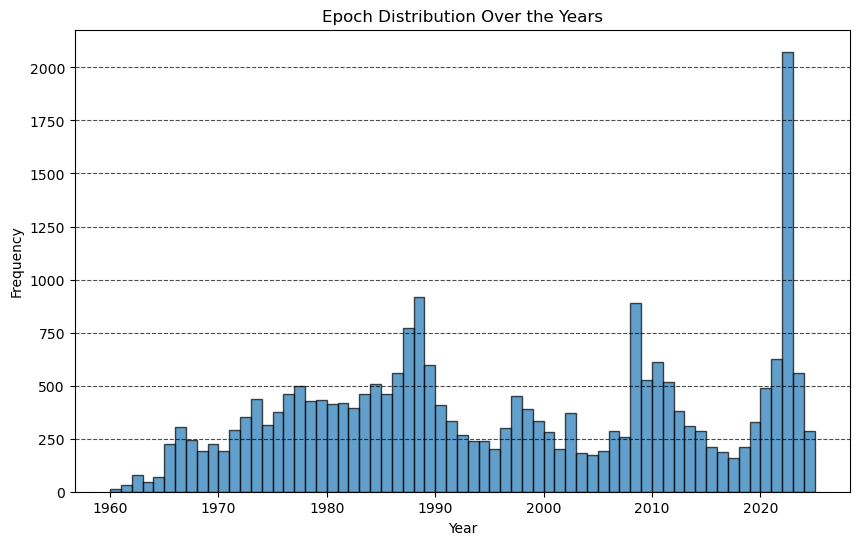

In [ ]:
# Visualize the epoch distribution
RandomEpochsVisual_df = pd.read_csv('../Data/RandomEpochs.csv')
RandomEpochsVisual_df['EPOCH'] = pd.to_datetime(RandomEpochsVisual_df['EPOCH'])

# Extract the year from the epoch column
RandomEpochsVisual_df['EPOCH'] = RandomEpochsVisual_df['EPOCH'].dt.year

# Plot the distribution of epochs over the years
plt.figure(figsize=(10, 6))
plt.hist(RandomEpochsVisual_df['EPOCH'], bins=range(RandomEpochsVisual_df['EPOCH'].min(), RandomEpochsVisual_df['EPOCH'].max() + 1), edgecolor='black', alpha=0.7)
plt.title('Epoch Distribution Over the Years')
plt.xlabel('Year')
plt.ylabel('Frequency')
plt.grid(axis='y', color='black', linestyle='--', alpha=0.7)
plt.show()

## 3. Query the full OMM for each object for the randomly selected Epoch

In [231]:
def re_login():
    # read Space-Track.org credentials from external file (username in line 1, password in line 2)
    with open('../SpaceTrackCredentials.txt', 'r') as file:
        credentials = file.read().splitlines()

    username = credentials[0]
    password = credentials[1]

    # create a SpaceTrackClient instance
    st = SpaceTrackClient(username, password) 

    try:
        # Try fetching a single SATCAT entry to verify authentication
        test_data = st.gp(limit=1, format='json')
        print("Successfully re-logged in to Space-Track.org!")
    except Exception as e:
        print(f"Failed to authenticate with Space-Track.org: {e}")

In [ ]:
# Load the data
RandomEpochs_df = pd.read_csv('../Data/RandomEpochs.csv')

# DataFrame to store full OMM data if first execution
# OMMs_list = []

# define start index
start_index = 20274

# Iterate over the DataFrame and query full OMM for each NORAD ID and Epoch
for index, row in RandomEpochs_df.iloc[start_index:].iterrows():
    norad_id = row['NORAD_CAT_ID']
    epoch = row['EPOCH']
    
    # Extract the date part from the epoch
    start_date = epoch.split("T")[0]
    end_date = (datetime.strptime(start_date, '%Y-%m-%d') + timedelta(days=1)).strftime('%Y-%m-%d')
    api_url = f"https://www.space-track.org/basicspacedata/query/class/gp_history/NORAD_CAT_ID/{norad_id}/EPOCH/>{start_date},<{end_date}/limit/1/format/json"
    
    retry = True
    retry_count = 0

    while retry and retry_count < 3:
        retry = False
        retry_count += 1
         # try fetching data
        try:
            response = st.gp_history(norad_cat_id=norad_id, epoch=f">{start_date},<{end_date}", limit=1, format='json')
            # Retry once after 60 seconds if rate-limited
            if "You've violated your query rate limit" in response:
                print(f"({index}) *** Rate limit hit for NORAD ID {norad_id}. Retrying in 60 seconds... ***")
                time.sleep(60)
                response = st.gp_history(norad_cat_id=norad_id, epoch=f">{start_date},<{end_date}", limit=1, format='json')
                # Skip if still rate-limited
                if "You've violated your query rate limit" in response:
                    print(f"({index}) *** Still rate-limited after retry. Skipping NORAD ID {norad_id} ***")
                    continue
            OMMs_list.extend(json.loads(response))
            print(f"({index}) Successfully retrieved OMM data for NORAD ID {norad_id}")
        # catch exceptions
        except Exception as e:
            if "401" in str(e):
                print(f"({index}) *** Error: {e} \nRe-authenticating...")
                re_login()
                retry = True
            else:
                print(f"({index}) *** Error: {e} for NORAD ID {norad_id} *** \nAPI URL: {api_url} \nWaiting for 60 seconds before retrying...")
                time.sleep(60)
                retry = True
        
    if retry_count >= 3:
        print(f"({index}) *** Skipping NORAD ID {norad_id} after 3 retries ***")
    
    # Save data to CSV every 10 iterations
    if (index + 1) % 100 == 0:
        OMMs_df = pd.DataFrame(OMMs_list)
        OMMs_df.to_csv('../Data/OMMs.csv', index=False)
        print(f"Saved OMM data to csv. Total OMMs retrieved: {len(OMMs_df)}")

# Save the final data to a CSV file
OMMs_df = pd.DataFrame(OMMs_list)
OMMs_df.to_csv('../Data/OMMs.csv', index=False)

print(f"\nRetrieved full OMM data for {len(OMMs_df)} NORAD IDs. {len(RandomEpochs_df) - len(OMMs_df)} objects are missing OMM data.")

(20274) Successfully retrieved OMM data for NORAD ID 39589
(20275) Successfully retrieved OMM data for NORAD ID 39590
(20276) Successfully retrieved OMM data for NORAD ID 39593
(20277) Successfully retrieved OMM data for NORAD ID 39595
(20278) Successfully retrieved OMM data for NORAD ID 39596
(20279) Successfully retrieved OMM data for NORAD ID 39597
(20280) Successfully retrieved OMM data for NORAD ID 39601
(20281) Successfully retrieved OMM data for NORAD ID 39604
(20282) Successfully retrieved OMM data for NORAD ID 39610
(20283) Successfully retrieved OMM data for NORAD ID 39611
(20284) Successfully retrieved OMM data for NORAD ID 39615
(20285) Successfully retrieved OMM data for NORAD ID 39619
(20286) Successfully retrieved OMM data for NORAD ID 39623
(20287) Successfully retrieved OMM data for NORAD ID 39649
(20288) Successfully retrieved OMM data for NORAD ID 39686
(20289) Successfully retrieved OMM data for NORAD ID 39687
(20290) Successfully retrieved OMM data for NORAD ID 397

In [ ]:
# Identify missing NORAD IDs
OMMs_df['NORAD_CAT_ID'] = OMMs_df['NORAD_CAT_ID'].astype(int) # convert column to int
retrieved_ids = set(OMMs_df['NORAD_CAT_ID'])
all_ids = set(RandomEpochs_df['NORAD_CAT_ID'])

missing_ids = all_ids - retrieved_ids
print(f"\nMissing NORAD IDs: {len(missing_ids)}")



Missing NORAD IDs: 105


In [297]:
# two ids must have been retrieved twice
# check if there are any duplicates in the retrieved data
duplicates = OMMs_df[OMMs_df.duplicated(subset=['NORAD_CAT_ID'], keep=False)]
print(f"\nDuplicate NORAD IDs: {duplicates['NORAD_CAT_ID'].unique()}")


Duplicate NORAD IDs: [18977 18978]


In [298]:
# delete duplicates
OMMs_df = OMMs_df.drop_duplicates(subset=['NORAD_CAT_ID'], keep='first')
OMMs_df.to_csv('../Data/OMMs.csv', index=False)
print(f"\nRemoved duplicates. Total OMMs retrieved: {len(OMMs_df)}")


Removed duplicates. Total OMMs retrieved: 24369


In [302]:
# query missing ids
# Filter the rows in RandomEpochs_df for missing NORAD IDs
missing_data_df = RandomEpochs_df[RandomEpochs_df['NORAD_CAT_ID'].isin(missing_ids)]
initial_length = len(OMMs_df)
retry = False

# Iterate over the DataFrame and query full OMM for each missing NORAD ID and Epoch
for index, row in missing_data_df.iterrows():
    norad_id = row['NORAD_CAT_ID']
    epoch = row['EPOCH']
    
    # Extract the date part from the epoch
    start_date = epoch.split("T")[0]
    end_date = (datetime.strptime(start_date, '%Y-%m-%d') + timedelta(days=1)).strftime('%Y-%m-%d')
    api_url = f"https://www.space-track.org/basicspacedata/query/class/gp_history/NORAD_CAT_ID/{norad_id}/EPOCH/>{start_date},<{end_date}/limit/1/format/json"

    retry = True
    while retry:
        retry = False
        # Try fetching data
        try:
            response = st.gp_history(norad_cat_id=norad_id, epoch=f">{start_date},<{end_date}", limit=1, format='json')
            # Retry once after 60 seconds if rate-limited
            if "You've violated your query rate limit" in response:
                print(f"({index}) *** Rate limit hit for NORAD ID {norad_id}. Retrying in 60 seconds... ***")
                time.sleep(60)
                retry = True
                continue
            new_data = pd.DataFrame(json.loads(response)) # Convert the response to a DataFrame
            if not new_data.empty:
                OMMs_df = pd.concat([OMMs_df, new_data], ignore_index=True)
                print(f"({index}) Successfully retrieved OMM data for NORAD ID {norad_id}")
            else:
                print(f"({index}) No data returned for NORAD ID {norad_id}")
        # Catch exceptions
        except Exception as e:
            if "401" in str(e):
                print(f"({index}) *** Error: {e} \nRe-authenticating...")
                re_login()
                retry = True
            else:
                print(f"({index}) *** Error: {e} for NORAD ID {norad_id} *** \nAPI URL: {api_url} \nWaiting for 60 seconds before retrying...")
                time.sleep(60)
                retry = True

# Save the final updated OMM data to a CSV file
OMMs_df.to_csv('../Data/OMMs.csv', index=False)
print(f"\nAdded {len(OMMs_df) - initial_length} new rows to OMMs_df.")

(186) Successfully retrieved OMM data for NORAD ID 476
(187) Successfully retrieved OMM data for NORAD ID 477
(188) Successfully retrieved OMM data for NORAD ID 479
(189) Successfully retrieved OMM data for NORAD ID 482
(190) Successfully retrieved OMM data for NORAD ID 483
(191) Successfully retrieved OMM data for NORAD ID 484
(192) Successfully retrieved OMM data for NORAD ID 485
(193) Successfully retrieved OMM data for NORAD ID 486
(194) Successfully retrieved OMM data for NORAD ID 487
(195) Successfully retrieved OMM data for NORAD ID 488
(196) Successfully retrieved OMM data for NORAD ID 489
(197) Successfully retrieved OMM data for NORAD ID 491
(198) Successfully retrieved OMM data for NORAD ID 492
(199) Successfully retrieved OMM data for NORAD ID 493
(200) Successfully retrieved OMM data for NORAD ID 494
(201) Successfully retrieved OMM data for NORAD ID 495
(202) Successfully retrieved OMM data for NORAD ID 496
(203) Successfully retrieved OMM data for NORAD ID 497
(204) Succ

## 4. Inspect data to see which columns are unneccecary 

In [307]:
# inspect certain columns to see if they can be dropped
print(OMMs_df['ORIGINATOR'].unique())
print(OMMs_df['CENTER_NAME'].unique())
print(OMMs_df['REF_FRAME'].unique())
print(OMMs_df['TIME_SYSTEM'].unique())
print(OMMs_df['MEAN_ELEMENT_THEORY'].unique())
print(OMMs_df['EPHEMERIS_TYPE'].unique())
print(OMMs_df['CLASSIFICATION_TYPE'].unique())
print(OMMs_df['ELEMENT_SET_NO'].unique())

['18 SPCS']
['EARTH']
['TEME']
['UTC']
['SGP4']
['0' '3' '1']
['U']
['999']


In [ ]:
# drop not needed columns
OMMs_df.drop(columns=['CCSDS_OMM_VERS', 'COMMENT', 'CREATION_DATE', 'ORIGINATOR', 'CENTER_NAME', 'REF_FRAME', 'TIME_SYSTEM', 'MEAN_ELEMENT_THEORY', 'EPHEMERIS_TYPE', 'CLASSIFICATION_TYPE', 'ELEMENT_SET_NO', 'FILE', 'GP_ID', 'TLE_LINE0', 'TLE_LINE1', 'TLE_LINE2', 'COUNTRY_CODE'], inplace=True)

,OBJECT_NAME,OBJECT_ID,EPOCH,MEAN_MOTION,ECCENTRICITY,INCLINATION,RA_OF_ASC_NODE,ARG_OF_PERICENTER,MEAN_ANOMALY,NORAD_CAT_ID,...,MEAN_MOTION_DDOT,SEMIMAJOR_AXIS,PERIOD,APOAPSIS,PERIAPSIS,OBJECT_TYPE,RCS_SIZE,LAUNCH_DATE,SITE,DECAY_DATE
0,JUNO II R/B,1959-009B,1982-01-13T15:21:06.439968,14.78334522,0.01830930,50.3043,233.6360,296.4831,61.7000,23,...,0.0000000000000,7012.727,97.406,762.990,506.194,ROCKET BODY,MEDIUM,1959-10-13,AFETR,1989-07-16
1,THOR ABLE R/B,1960-002A,1987-09-12T00:12:35.555904,14.85180529,0.00176210,48.3748,236.4746,95.6844,264.6079,28,...,0.0000000000000,6991.160,96.957,625.344,600.706,ROCKET BODY,LARGE,1960-04-01,AFETR,1991-07-03
2,TBA - TO BE ASSIGNED,1960-003A,1961-04-17T11:27:12.924288,15.65396693,0.01254160,51.2500,272.4964,204.3932,155.8967,30,...,0.0000000000000,6750.239,91.989,456.763,287.445,TBA,None,None,None,None
3,TBA - TO BE ASSIGNED,1960-003C,1960-08-06T21:56:44.331935,15.38109622,0.02437460,51.2879,72.6448,330.1842,30.5053,33,...,0.0000000000000,6829.840,93.621,618.180,285.231,TBA,None,None,None,None
4,TBA - TO BE ASSIGNED,1960-005B,1960-06-08T00:20:02.506559,15.86129145,0.00159900,64.8899,183.4791,52.6307,307.4432,35,...,0.0000000000000,6691.288,90.787,323.852,302.454,TBA,None,None,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24469,COSMOS 1408 DEB,1982-092BGE,2022-02-24T04:18:27.634464,15.39821031,0.00395950,82.5731,22.4446,120.0656,240.4526,51360,...,0.0000000000000,6824.775,93.517,473.663,419.617,DEBRIS,SMALL,1982-09-16,PKMTR,None
24470,COSMOS 1408 DEB,1982-092BGF,2022-08-12T05:05:19.433472,15.58686654,0.00387690,82.6444,208.0746,349.1608,10.8808,51361,...,0.0000000000000,6769.594,92.385,417.704,365.214,DEBRIS,SMALL,1982-09-16,PKMTR,None
24471,CZ-2C DEB,2022-043E,2022-08-08T03:36:31.257792,15.40041815,0.00135010,97.4579,296.7243,301.8644,122.3077,52324,...,0.0000000000000,6824.123,93.504,455.201,436.775,DEBRIS,MEDIUM,2022-04-29,JSC,None
24472,H-2A DEB,2018-084DR,2022-07-25T04:02:25.272384,15.01633748,0.00359250,97.9686,335.9968,19.5966,340.6629,53122,...,0.0000000000000,6939.995,95.896,586.792,536.928,DEBRIS,SMALL,2018-10-29,TNSTA,None


In [69]:
# Save OMMs to csv 
OMMs_df.to_csv('../Data/OMMs.csv', index=False)